# Timeseries — Permintaan Intermittent (banyak hari tanpa penjualan)
**Kapan dipakai:** penjualan harian per barang yang sering 0 (suku cadang, obat langka, toko
kecil). Model biasa meramal ~0 terus atau terlalu tinggi.

**Langkah:** tabel harian (hari tanpa transaksi diisi 0) → metode khusus: **Croston**, **SBA**
(Croston dikoreksi bias), **TSB** (peluang terjual x besar penjualan) → bandingkan dengan naive
dan ramalan 0. Metrik: MAE dan RMSSE (bisa dibandingkan antar barang).

**Data demo:** 30 barang Online Retail UCI.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/timeseries/intermittent"   # GANTI saat lomba
SALES_CSV = f"{DATA_FOLDER}/retail_harian.csv"

ITEM_COL = "item"
DATE_COL = "date"
VALUE_COL = "qty"
HORIZON = 28        # hari ramalan, data uji = HORIZON hari terakhir
ALPHA = 0.1         # kecepatan belajar besar penjualan
BETA = 0.1          # kecepatan belajar peluang terjual (TSB)

## Baca data → tabel harian (baris = hari, kolom = barang)

In [3]:
sales = pd.read_csv(SALES_CSV, parse_dates=[DATE_COL])
daily = sales.pivot_table(index=DATE_COL, columns=ITEM_COL, values=VALUE_COL, aggfunc="sum")
daily = daily.asfreq("D")     # hari tanpa transaksi muncul sebagai NaN
daily = daily.fillna(0)
print(sales.shape, "→ tabel harian", daily.shape)
print("porsi hari tanpa penjualan:", round((daily == 0).mean().mean(), 3))
daily.iloc[:8, :6]

(2252, 3) → tabel harian (374, 30)
porsi hari tanpa penjualan: 0.799


item,20986,21039,21061,21243,21262,21584
date,,,,,,
2010-12-01,0.0,0.0,12.0,1.0,0.0,13.0
2010-12-02,4.0,1.0,12.0,0.0,0.0,27.0
2010-12-03,4.0,0.0,0.0,8.0,0.0,0.0
2010-12-04,0.0,0.0,0.0,0.0,0.0,0.0
2010-12-05,0.0,0.0,0.0,9.0,0.0,14.0
2010-12-06,7.0,1.0,0.0,0.0,6.0,2.0
2010-12-07,0.0,0.0,0.0,0.0,0.0,0.0
2010-12-08,0.0,2.0,12.0,3.0,0.0,12.0


## EDA: jenis permintaan (Syntetos-Boylan)
ADI = rata-rata jarak antar penjualan, CV² = variasi besar penjualan.
ADI > 1.32 dan CV² < 0.49 → intermittent, keduanya tinggi → lumpy, hanya CV² tinggi →
erratic, keduanya rendah → smooth.

kind
lumpy           29
intermittent     1
Name: count, dtype: int64


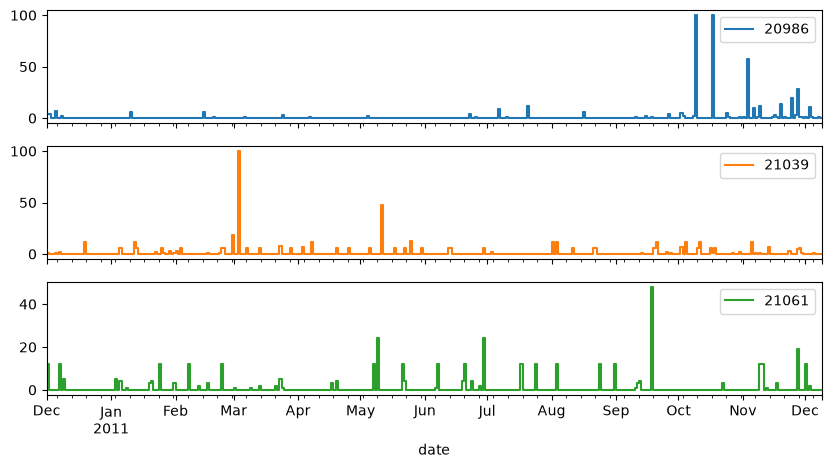

In [4]:
nonzero = daily[daily > 0]
demand_type = pd.DataFrame(index=daily.columns)
demand_type["ADI"] = len(daily) / (daily > 0).sum()
demand_type["CV2"] = nonzero.std() ** 2 / nonzero.mean() ** 2
kinds = []
for adi, cv_squared in zip(demand_type["ADI"], demand_type["CV2"]):
    if adi > 1.32 and cv_squared < 0.49:
        kinds.append("intermittent")
    elif adi > 1.32:
        kinds.append("lumpy")
    elif cv_squared >= 0.49:
        kinds.append("erratic")
    else:
        kinds.append("smooth")
demand_type["kind"] = kinds
print(demand_type["kind"].value_counts())
daily.iloc[:, :3].plot(subplots=True, figsize=(10, 5), drawstyle="steps")
plt.show()

## Split waktu

In [5]:
train = daily.iloc[:-HORIZON]
test = daily.iloc[-HORIZON:]
print("latih:", train.shape, "| uji:", test.shape)

latih: (346, 30) | uji: (28, 30)


## Metode (ditulis manual, masing-masing menghasilkan satu angka ramalan per hari)
Croston: besar penjualan dan jarak antar penjualan dihaluskan terpisah, ramalan = besar / jarak.

In [6]:
def croston(values):
    sale_days = np.flatnonzero(values)                    # nomor hari yang ada penjualan
    gaps = np.diff(np.concatenate([[-1], sale_days]))     # jarak antar hari penjualan
    size = values[sale_days[0]]
    interval = gaps[0]
    for demand, gap in zip(values[sale_days[1:]], gaps[1:]):
        size = size + ALPHA * (demand - size)
        interval = interval + ALPHA * (gap - interval)
    return size / interval


def sba(values):
    return croston(values) * (1 - ALPHA / 2)


example = train.iloc[:, 0].to_numpy()     # barang pertama
print("Croston:", round(croston(example), 3), "| SBA:", round(sba(example), 3))

Croston: 2.963 | SBA: 2.815


TSB: peluang terjual dan besar penjualan dihaluskan terpisah, ramalan = peluang x besar.

In [7]:
def tsb(values):
    size = values[values > 0].mean()
    probability = (values > 0).mean()
    for demand in values:
        probability = probability + BETA * ((demand > 0) - probability)
        if demand > 0:
            size = size + ALPHA * (demand - size)
    return probability * size


def mean_last_28(values):
    return values[-28:].mean()


print("TSB:", round(tsb(example), 3), "| rata-rata 28 hari:", round(mean_last_28(example), 3))

TSB: 6.653 | rata-rata 28 hari: 6.714


## Model
Pilih SATU metode: hapus `#` di baris yang ingin dipakai, beri `#` pada baris SBA.

In [8]:
method = sba
# method = croston
# method = tsb
# method = np.mean          # rata-rata semua hari
# method = mean_last_28     # rata-rata 28 hari terakhir

## Evaluasi: MAE dan RMSSE per barang, dibanding pembanding sederhana
MAE memihak ramalan 0 (median permintaan intermittent = 0), padahal stok 0 tidak berguna.
Karena itu pilih metode dengan RMSSE terkecil (dipakai juga di lomba M5).

In [9]:
def rmsse(actual, forecast, history):
    return np.sqrt(np.mean((actual - forecast) ** 2) / np.mean(np.diff(history) ** 2))


def last_day(values):
    return values[-1]


def zero(values):
    return 0.0


scores = []
for name, function in [("model", method), ("naive (hari terakhir)", last_day), ("nol", zero)]:
    for item in daily.columns:
        history = train[item].to_numpy()
        forecast = function(history)
        actual = test[item].to_numpy()
        scores.append([name, item, np.mean(np.abs(actual - forecast)),
                       rmsse(actual, forecast, history)])
scores = pd.DataFrame(scores, columns=["method", "item", "MAE", "RMSSE"])
summary = scores.groupby("method")[["MAE", "RMSSE"]].mean()
print(summary.round(4))

                          MAE   RMSSE
method                               
model                  6.7810  0.8495
naive (hari terakhir)  7.9857  1.1196
nol                    5.5071  0.9193


## Latih ulang di semua data + hasil ramalan ke depan (satu baris per barang-hari)

In [10]:
future_dates = pd.date_range(start=daily.index[-1], periods=HORIZON + 1, freq="D")[1:]
forecasts = []
for item in daily.columns:
    forecasts.append(method(daily[item].to_numpy()))

result = pd.DataFrame()
result["item"] = np.repeat(daily.columns.to_numpy(), HORIZON)
result["date"] = np.tile(future_dates, len(daily.columns))
result["qty"] = np.repeat(forecasts, HORIZON)
result.to_csv("hasil.csv", index=False)
result.head()

,item,date,qty
0,20986,2011-12-10,2.855023
1,20986,2011-12-11,2.855023
2,20986,2011-12-12,2.855023
3,20986,2011-12-13,2.855023
4,20986,2011-12-14,2.855023
